# 37 · Serving and the enterprise map: an API, three replicas, a load test and a canary
Level L6 · Part 6 · core · ~40 min · builds on 14, 35, 36

## Goal
Serve the support desk as an HTTP API with FastAPI. Run three replicas of it on localhost, send them a burst of requests, and measure the wait at
the median and the tail. Roll out a new version to a small share of traffic (a canary) and compare it with the old one before it takes all the
traffic. Then place the service in an organisation: tenancy, governance, and disaster recovery. No model call is made; the desk here is the
scripted one, so the serving is what gets tested.

## Why it matters
An agent that works on a laptop is not a service. A service needs many requests at once, a wait that stays under a limit, a way to roll out a
change without breaking every customer, and an owner for each replica. A load test shows where the service breaks before a customer does, and a
canary shows whether a new version is worse before it reaches everyone.

| A laptop agent | A served agent |
|---|---|
| One request at a time | Many at once, on several replicas |
| "It seemed fast" | p50 and p95 measured under load |
| A new version replaces the old one | A canary takes a small share and is compared first |

## The idea
A **replica** is one running copy of the service; three replicas share the load. A **load test** sends a burst and measures the wait at the median
(p50) and the tail (p95). A **canary** sends a fixed share of requests to the new version and compares its results and waits with the old one.
The **enterprise map** places the service: which tenant owns its data, which runtime runs it, who may change it, and how it recovers.

## Picture
`show_mermaid` draws a Mermaid diagram from the text you give it; it lives in `graph_view.py` in the topic folder. The diagram shows the path of
one request: customers, a router, three replicas of v1, one canary replica of v2, and the shared state behind them.

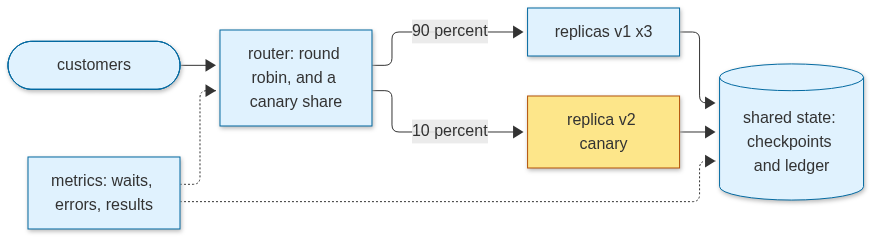

In [1]:
import sys; sys.path.insert(0, "../../..")  # the topic folder: llm_setup.py, graph_view.py, a2a_server.py and tut_env.py live there

from graph_view import show_mermaid

show_mermaid("""
flowchart LR
  C(["customers"]) --> G["router: round robin, and a canary share"]
  G -->|90 percent| V1["replicas v1 x3"]
  G -->|10 percent| V2["replica v2 canary"]
  V1 --> D[("shared state: checkpoints and ledger")]
  V2 --> D
  M["metrics: waits, errors, results"] -.-> G
  M -.-> D
  classDef code fill:#e0f2fe,stroke:#0369a1
  classDef new fill:#fde68a,stroke:#b45309
  class C,G,V1,D,M code
  class V2 new
""")

## Step by step
Six small steps, none with a model call. The desk is scripted, so what gets tested is the serving: the API, the replicas, the load and the rollout.

**Step 1 · the desk as an API (no call).** The desk is a one-node LangGraph graph: it looks up the order in the example data and writes the reply.
The graph is wrapped in a FastAPI application with one route, `POST /ask`. It takes a question and a customer id, runs the graph, and returns the
reply and the version that answered. The same code serves the real graph in lesson 14.

In [2]:
import json
from pathlib import Path

from fastapi import FastAPI
from pydantic import BaseModel
from langgraph.graph import END, START, StateGraph
from typing_extensions import TypedDict

ORDERS = json.loads((Path("../../../data") / "support_eval.json").read_text())["world"]["orders"]


class Ask(BaseModel):
    customer_id: str
    question: str


class DeskState(TypedDict):
    question: str
    reply: str


def answer(state: DeskState) -> dict:
    digits = [w.strip("?.,") for w in state["question"].split() if w.strip("?.,").isdigit()]
    row = ORDERS.get(digits[0]) if digits else None
    if row is None:
        return {"reply": "Please send the four-digit order number from your confirmation email."}
    return {"reply": f"Order {digits[0]} is {row['status']}, {row['days_late']} days late."}

**Step 1, part 2 · the graph and the app.** `desk` is the compiled graph. `make_app(version)` is a helper that builds one FastAPI app for one
version: `POST /ask` answers a question, and `GET /health` says the replica is up. The reply never echoes the customer id.

In [3]:
desk_graph = StateGraph(DeskState)
desk_graph.add_node("answer", answer)
desk_graph.add_edge(START, "answer").add_edge("answer", END)
desk = desk_graph.compile()


def make_app(version: str) -> FastAPI:
    app = FastAPI(title=f"support desk {version}")

    @app.post("/ask")
    def ask(body: Ask) -> dict:
        out = desk.invoke({"question": body.question, "reply": ""})
        return {"reply": out["reply"], "version": version, "customer": "redacted"}  # the id is never echoed back

    @app.get("/health")
    def health() -> dict:
        return {"ok": True, "version": version}

    return app


print(desk.invoke({"question": "Where is order 1003?", "reply": ""})["reply"])

Order 1003 is lost, 9 days late.


**Step 2 · three replicas on localhost (no call).** A replica is the same app on its own port. Two helpers start them. `free_port` asks the
operating system for an unused port. `start(version)` runs one replica in a background thread, waits until it is up, checks its `/health`, and
returns its address and its server handle, so that it can be stopped later. The v1 replicas serve the current version.

In [4]:
import socket
import threading
import time

import httpx
import uvicorn


def free_port() -> int:
    with socket.socket() as s:
        s.bind(("127.0.0.1", 0))
        return s.getsockname()[1]


def start(version: str) -> tuple[str, uvicorn.Server, threading.Thread]:
    port = free_port()
    server = uvicorn.Server(uvicorn.Config(make_app(version), host="127.0.0.1", port=port, log_level="warning"))
    thread = threading.Thread(target=server.run, daemon=True)
    thread.start()
    while not server.started:
        time.sleep(0.05)
    base = f"http://127.0.0.1:{port}"
    assert httpx.get(base + "/health").json()["ok"]
    return base, server, thread


v1 = [start("v1") for _ in range(3)]
print("replicas up:", len(v1))

replicas up: 3


**Step 3 · a load test (no call).** `one` sends one request and returns its wait in milliseconds. `load_test` sends all of them at once with
`asyncio.gather`, spreading them over the three replicas in turn. The median and the 95th percentile of the waits are reported. A tail that is much
larger than the median is the first sign of a queue.

In [5]:
import asyncio
import statistics

QUESTIONS = ["Where is order 1003?", "Order 1002 status please", "What about order 1005?", "order 2207?"] * 25


async def one(client: httpx.AsyncClient, base: str, question: str) -> float:
    start_t = time.perf_counter()
    r = await client.post(base + "/ask", json={"customer_id": "c-1", "question": question})
    r.raise_for_status()
    return (time.perf_counter() - start_t) * 1000


async def load_test(bases: list[str], questions: list[str]) -> list[float]:
    async with httpx.AsyncClient(timeout=10.0) as client:
        tasks = [one(client, bases[i % len(bases)], q) for i, q in enumerate(questions)]
        return await asyncio.gather(*tasks)


waits = await load_test([b for b, _, _ in v1], QUESTIONS)
p50 = statistics.median(waits)
p95 = sorted(waits)[int(0.95 * len(waits)) - 1]
print(f"{len(waits)} requests over 3 replicas · p50 {p50:.1f} ms · p95 {p95:.1f} ms")

100 requests over 3 replicas · p50 517.4 ms · p95 527.4 ms


**Step 4 · a canary: one request in ten goes to v2 (no call).** A v2 replica starts. `route(i)` sends every tenth request to it and the rest
round-robin over v1. `canary_run` then sends the same 100 questions one after another and keeps each version's waits and replies. The canary is
judged on the same questions: its replies must match v1's, and its waits are compared with v1's from this run. With ten canary requests the p95 is
a rough number; a real canary runs longer, on more traffic.

In [6]:
v2_base, v2_server, v2_thread = start("v2")
bases = [b for b, _, _ in v1]


def route(i: int) -> str:
    """Every tenth request goes to the canary; the others are spread over v1."""
    return v2_base if i % 10 == 9 else bases[i % len(bases)]


async def canary_run(questions: list[str]) -> tuple[dict, dict]:
    waits, replies = {"v1": [], "v2": []}, {}
    async with httpx.AsyncClient(timeout=10.0) as client:
        for i, q in enumerate(questions):
            t0 = time.perf_counter()
            r = (await client.post(route(i) + "/ask", json={"customer_id": "c-1", "question": q})).json()
            waits[r["version"]].append((time.perf_counter() - t0) * 1000)
            replies.setdefault(q, set()).add(r["reply"])
    return waits, replies


canary_waits, replies = await canary_run(QUESTIONS)
same = all(len(v) == 1 for v in replies.values())
v1_p95 = sorted(canary_waits["v1"])[int(0.95 * len(canary_waits["v1"])) - 1]
v2_p95 = sorted(canary_waits["v2"])[int(0.95 * len(canary_waits["v2"])) - 1]
print("requests by version:", {k: len(v) for k, v in canary_waits.items()}, "· same replies:", same)
print(f"p95 in this run · v1 {v1_p95:.1f} ms · v2 {v2_p95:.1f} ms")

requests by version: {'v1': 90, 'v2': 10} · same replies: True
p95 in this run · v1 3.6 ms · v2 3.4 ms


**Step 5 · the decision (no call).** The rule is written before the canary is judged, and it is code, so the same numbers always give the same
decision. v2 takes more traffic only if its replies match v1's and its p95 is at most 20 percent above v1's. `promote` returns the decision. The
first print judges this run's numbers, so its outcome depends on the timing of this run.

In [7]:
def promote(v1_p95: float, v2_p95: float, same_replies: bool) -> str:
    if not same_replies:
        return "hold: the canary's replies differ from v1"
    if v2_p95 > 1.2 * v1_p95:
        return "hold: the canary is more than 20 percent slower at p95"
    return "promote: send the canary more traffic"


print("this run:", promote(v1_p95, v2_p95, same))

this run: promote: send the canary more traffic


**The three fixed cases.** The same rule on set numbers, so each branch is visible whatever this run measured: a canary within 20 percent is
promoted, a canary 30 percent slower is held, and a canary whose replies differ is held.

In [8]:
for case in [(10.0, 10.5, True), (10.0, 13.0, True), (10.0, 10.0, False)]:
    print(case, "->", promote(*case))

(10.0, 10.5, True) -> promote: send the canary more traffic
(10.0, 13.0, True) -> hold: the canary is more than 20 percent slower at p95
(10.0, 10.0, False) -> hold: the canary's replies differ from v1


**Step 6 · stop the replicas (no call).** Each server gets `should_exit`, and the lesson waits for each thread to finish, so the ports are free
for the next run.

In [9]:
replicas = v1 + [(v2_base, v2_server, v2_thread)]
for _, server, _ in replicas:
    server.should_exit = True
for _, _, thread in replicas:
    thread.join(timeout=5)
print("servers still running:", sum(t.is_alive() for _, _, t in replicas))

servers still running: 0


## The enterprise map
Four questions a reviewer asks before a service goes live, drawn as one map: tenancy (whose data), runtime (where it runs), governance (who may
change it) and recovery (how it comes back). Each box is the answer this course uses.

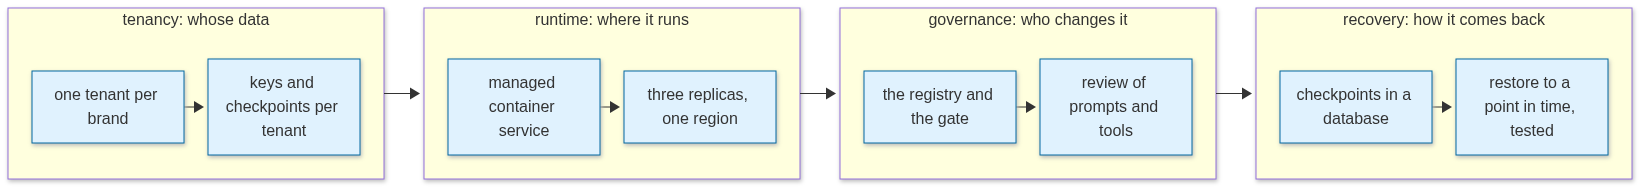

In [10]:
show_mermaid("""
flowchart LR
  subgraph T["tenancy: whose data"]
    T1["one tenant per brand"] --> T2["keys and checkpoints per tenant"]
  end
  subgraph R["runtime: where it runs"]
    R1["managed container service"] --> R2["three replicas, one region"]
  end
  subgraph G["governance: who changes it"]
    G1["the registry and the gate"] --> G2["review of prompts and tools"]
  end
  subgraph D["recovery: how it comes back"]
    D1["checkpoints in a database"] --> D2["restore to a point in time, tested"]
  end
  T --> R --> G --> D
  classDef code fill:#e0f2fe,stroke:#0369a1
  class T1,T2,R1,R2,G1,G2,D1,D2 code
""")

## At real scale
- Teams roll out by canary and promote on a written rule, not on a feeling. Anthropic's engineering team describes "rainbow" deployments for its
  multi-agent research system, where old and new agents run side by side while traffic moves. The rule and its numbers are reviewed, like a release
  → lesson 32 (evals in CI).
- The first walls are provider quotas, cost and tail latency, not CPU. Teams alert on p95 and on the error rate, and cap spend per task and per
  tenant at a gateway → lessons 33 and 36.
- A replica can be replaced safely only if its state lives outside it. Checkpoints sit in a database, so a killed replica's run resumes on
  another one. The kill drill in lesson 35 is the small version of that test.

## Decision guide
| Question | Answer in this lesson |
|---|---|
| Is the wait good enough for customers? | Read p95 with p50 from the load test (Step 3); never the average alone |
| Should v2 take more traffic? | Only when the written rule says promote (Step 5), judged on the same questions |
| Do I need more replicas? | When the tail breaks the limit and the provider quota still has room; replicas do not fix a slow tool |
| Where does the state live? | Outside the replica, in a database; then a replica can be stopped safely → lesson 35 |
| Who may change a prompt or a tool? | Only through the registry and the review gate (governance in the map) |

## What just happened
- `replicas up: 3`: each replica answered its `/health` check before it took traffic.
- The load test printed a p50 and a p95 for 100 requests over three replicas. Read the two together: the p95 is the tail a customer can feel.
- `requests by version: {'v1': 90, 'v2': 10}`: one request in ten reached the canary, and `same replies: True` shows the two versions answered alike.
- `servers still running: 0`: every replica stopped. The "this run" decision follows the timing of that run; the three fixed cases always print
  the same branches.

## Common mistakes
1. **Judging a service by its average.** The tail decides the experience. Report p95 with the median, as Step 3 does.
2. **A canary with no rule.** Without a written rule, the canary is promoted because nobody complained. Step 5 is the rule, and the fixed cases
   show what it decides.
3. **Calling a replica after it is stopped.** A stopped replica refuses connections. The cell below tries one and prints the real error (its name
   and first line only). Restart the replica with `start` before sending it traffic again.
4. **Echoing the customer's id back.** A reply that repeats the id leaks it to every log between the client and the service, as the desk does not.

In [11]:
try:
    httpx.get(v1[0][0] + "/health")
except httpx.ConnectError as err:
    print(type(err).__name__, "|", str(err).splitlines()[0])

ConnectError | [Errno 111] Connection refused


## Try it
Write `p95(waits)` that returns the 95th percentile of a list of waits, using the same rule as Step 3 (the element at index `int(0.95 * n) - 1` of the
sorted list). Test it on `[1, 2, 3, ..., 100]`. No model call is needed.

In [12]:
# your code here

**Answer** — try it first, then expand the hidden cell below.

In [13]:
def p95(waits: list[float]) -> float:
    return sorted(waits)[int(0.95 * len(waits)) - 1]


print(p95(list(range(1, 101))))  # 95

95


## Key terms
- **Replica** — one running copy of a service; several replicas share the load.
- **Router** — the part that picks which replica or version answers each request.
- **Load test** — a burst of requests sent at once to measure the waits.
- **p50 and p95** — the median wait, and the wait that 95 of 100 requests beat (the tail).
- **Canary** — a small share of traffic sent to the new version and compared before the rest moves.
- **Rollout rule** — the written condition for promoting a canary, fixed before the test.
- **Tenancy** — whose data, keys and checkpoints a service uses.

## Recap
- A service is an API with replicas; a load test measures the median and the tail.
- A canary sends a share of traffic to the new version, and a written rule decides whether it is promoted.
- The enterprise map places the service: tenancy, runtime, governance and recovery.

**Interview:** "How do you release a new version of an agent service without a bad day for customers?" Strong answer: "A canary on a small share of
traffic, compared with the old version on the same questions and on the tail latency, under a rule written before the release. Promotion is a
decision the rule makes, and rollback is a step I have tested."